In [2]:
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, classification_report)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_sample_weight

import pandas as pd
import preprocessing as pp
import encoding as enc
import matplotlib.pyplot as plt
import seaborn as sns
import graphviz


We preprocess the data first using an external python script

In [3]:
raw = pp.load_raw()
df = pp.clean(raw)

pp.cleaning_report(raw, df)

,rows,columns,duplicate rows,cells missing,text columns
raw,2930,82,0,719,43
cleaned,2930,77,0,649,39


We encode the invalid columns, split Sale Price into 6 classes and then we check for proportionality

In [4]:
target = enc.make_target(df)


class_counts = target.value_counts().sort_index()

class_percentages = (
    target
    .value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

display(class_distribution)

y = enc.make_target(df)

X = df.drop(columns=['SalePrice', 'Price Class'], errors='ignore')

X = enc.encode_features(X)



,Count,Percentage
SalePrice,,
0,237,8.09
1,509,17.37
2,1037,35.39
3,686,23.41
4,397,13.55
5,64,2.18


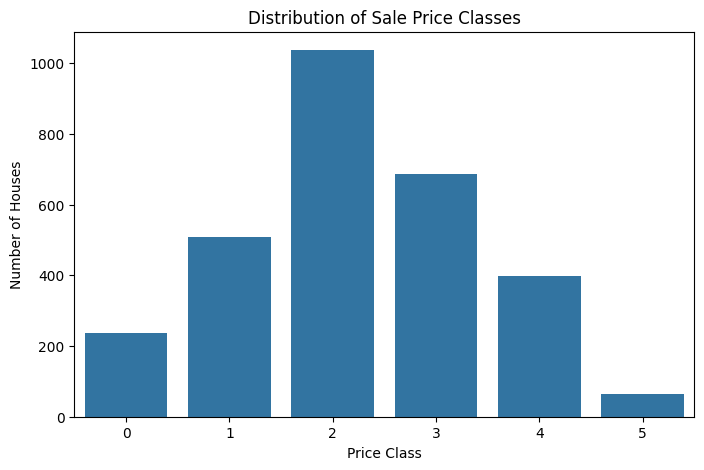

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(x=target)

plt.title("Distribution of Sale Price Classes")
plt.xlabel("Price Class")
plt.ylabel("Number of Houses")

plt.show()

The classes are very uneven. Class 2 has way more houses than class 5.

This means that:
- accuracy is a bad metric here, since always guessing class 2 already gets 35%
- the rare classes decide macro-f1, so that is the number we optimise

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

A first model with reasonable defaults, to have something to compare against.
Split is 80/20 stratified, imputation is fit on the training set only.

----

Let's check the structure of the dataset now

In [7]:
print(X_train.shape)
print(X_test.shape)

X_train.head()


(2344, 222)
(586, 222)


,Lot Frontage,Lot Area,Lot Shape,Land Slope,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Exter Qual,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
2354,81.0,10530,0.0,0.0,6,6,1975,2000,248.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1621,NaN,10147,1.0,0.0,6,5,1994,1994,32.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1155,95.0,19508,0.0,0.0,6,5,1974,1974,144.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2674,65.0,7800,0.0,0.0,5,7,1939,1950,0.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1343,NaN,6120,0.0,0.0,5,6,1945,1995,0.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


We can see that due to our encoding the dataset gained more columns

In [8]:
missing = X_train.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False).head(20))

Lot Frontage     399
Garage Yr Blt    123
dtype: int64

We replace missing values with the Median values

In [9]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [10]:
print("Missing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

Missing values in training: 0
Missing values in testing: 0


Now we implement the XGBoost and train it. We will then test its baseline accuracy and macro_f1

In [11]:
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=6,
    eval_metric='mlogloss',
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

In [12]:
xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets impo

In [13]:
y_pred = xgb_model.predict(X_test)

y_prob = xgb_model.predict_proba(X_test)

In [14]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("Macro F1:", f1_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

Accuracy: 0.7713310580204779
Precision: 0.7678737093431777
Recall: 0.7173302691172422
Macro F1: 0.7380310010878772

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.67      0.70        48
           1       0.70      0.68      0.69       102
           2       0.78      0.86      0.81       207
           3       0.81      0.74      0.78       137
           4       0.80      0.82      0.81        79
           5       0.78      0.54      0.64        13

    accuracy                           0.77       586
   macro avg       0.77      0.72      0.74       586
weighted avg       0.77      0.77      0.77       586



Macro-f1 is 0.738 while accuracy is 0.771. The gap comes from class 5, with
recall a way lower recall of 0.54. The model finds fewer than half of the expensive houses.

----

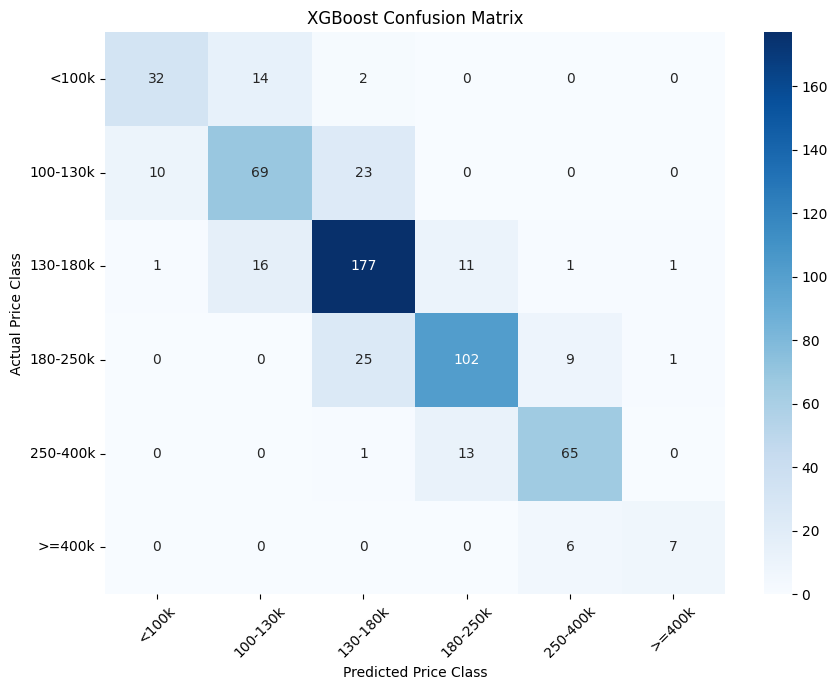

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=enc.price_labels,
    yticklabels=enc.price_labels
)

plt.xlabel("Predicted Price Class")
plt.ylabel("Actual Price Class")
plt.title("XGBoost Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Almost every mistake lands next to the diagonal since the classes
are arbitrary cuts on a continuous price, so a house at 179k and one at 181k
look identical to the model but belong to different classes.

The edge classes have it easier since they only have a neighbor that they can be confused with.

In [16]:
import numpy as np
import xgboost as xgb
import optuna

from sklearn.model_selection import cross_validate
from sklearn.impute import SimpleImputer

c:\Users\shoml\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
def make_data(drop_low_variance=True):
    # load -> clean -> encode, returns X and the 6 price classes
    df = pp.clean(pp.load_raw(), drop_low_variance=drop_low_variance)
    y = enc.make_target(df)
    X = enc.encode_features(df.drop(columns=enc.target_cols, errors='ignore'))
    return X, y


def impute(X_train, X_test):
    # median imputation fitted only on the training fold
    imp = SimpleImputer(strategy='median')
    X_train = pd.DataFrame(imp.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_test = pd.DataFrame(imp.transform(X_test), columns=X_test.columns, index=X_test.index)
    return X_train, X_test


def make_model(**params):
    # baseline parameters, can be overridden one by one
    base = dict(
        objective='multi:softprob',
        num_class=enc.n_classes,
        eval_metric='mlogloss',
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        tree_method='hist'
    )
    base.update(params)
    return XGBClassifier(**base)


X, y = make_data()
print(X.shape, y.value_counts().sort_index().to_dict())

(2930, 222) {0: 237, 1: 509, 2: 1037, 3: 686, 4: 397, 5: 64}


Let's check the impact of  stratification on 10% and 20% splits

In [18]:
def run_split(X, y, test_size, stratify):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42,
        stratify=y if stratify else None
    )
    X_tr, X_te = impute(X_tr, X_te)

    model = make_model()
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)

    return {
        'test_size': test_size,
        'stratify': stratify,
        'accuracy': accuracy_score(y_te, pred),
        'macro_f1': f1_score(y_te, pred, average='macro', zero_division=0),
        'smallest_class_in_test': y_te.value_counts().min()
    }


results = [run_split(X, y, ts, st) for ts in (0.1, 0.2) for st in (False, True)]
split_results = pd.DataFrame(results)
display(split_results)

,test_size,stratify,accuracy,macro_f1,smallest_class_in_test
0,0.1,False,0.774744,0.723039,10
1,0.1,True,0.767918,0.766706,6
2,0.2,False,0.767918,0.724519,20
3,0.2,True,0.771331,0.738031,13


Stratification helps in both cases: macro-f1 goes from 0.723 to 0.767 at 10%,
and from 0.725 to 0.738 at 20%. Accuracy barely moves, because it is driven by
the big classes; macro-f1 weights all six classes equally, so it reacts to how
well the rare ones are represented.


The 10% stratified split looks like the best result, but it is not a better
model. Its test set has only 6 houses in class 5, so a single prediction is
worth ~8% of that class's recall. The 20% split keeps 13 of them and gives a
far more stable estimate, which is why we use a stratified 80/20 split from
here on.

---

We compare k-fold validation with k=5 and k=10

In [19]:
def run_cv(X, y, k, model=None):
    X_imp = pd.DataFrame(
        SimpleImputer(strategy='median').fit_transform(X),
        columns=X.columns
    )
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

    scores = cross_validate(
        model if model is not None else make_model(),
        X_imp, y, cv=cv, scoring='f1_macro',
        return_train_score=True, n_jobs=-1
    )

    return {
        'k': k,
        'train_f1': scores['train_score'].mean(),
        'val_f1': scores['test_score'].mean(),
        'val_std': scores['test_score'].std(),
        'gap': scores['train_score'].mean() - scores['test_score'].mean()
    }


cv_results = pd.DataFrame([run_cv(X, y, 5), run_cv(X, y, 10)])
display(cv_results)

,k,train_f1,val_f1,val_std,gap
0,5,0.987707,0.734441,0.014519,0.253266
1,10,0.983789,0.745924,0.041205,0.237865


Cross validation and bias-variance

`gap` = train_f1 - val_f1 measures overfitting directly. It is around 0.25 for both
k values: the model reaches 0.99 on train and 0.73-0.75 on validation, so it
memorises a large part of the training set.

With k=10 there are more folds, each one smaller (~293 houses instead of ~586).
Smaller validation sets give noisier scores, which is why `val_std` jumps from
0.015 to 0.041. In exchange each model trains on 90% of the data instead of
80%, so the estimate is less pessimistic: val_f1 0.746 vs 0.734.

We use k=5 for the rest: the estimate is more stable and runs twice as fast,
which matters for Optuna.


In [20]:
def run_weighting(X, y, mode):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    X_tr, X_te = impute(X_tr, X_te)

    w = None
    if mode == 'balanced':
        w = compute_sample_weight('balanced', y_tr)
    elif mode == 'sqrt':
        # softer version of balanced weights
        w = np.sqrt(compute_sample_weight('balanced', y_tr))

    model = make_model()
    model.fit(X_tr, y_tr, sample_weight=w)
    pred = model.predict(X_te)

    row = {
        'mode': mode,
        'accuracy': accuracy_score(y_te, pred),
        'macro_f1': f1_score(y_te, pred, average='macro', zero_division=0)
    }
    # recall per class, to see what happens with the rare ones
    rec = recall_score(y_te, pred, average=None, zero_division=0)
    for i, r in enumerate(rec):
        row[f'recall_{i}'] = round(r, 3)
    return row


weight_results = pd.DataFrame([run_weighting(X, y, m) for m in ('none', 'sqrt', 'balanced')])
display(weight_results)

,mode,accuracy,macro_f1,recall_0,recall_1,recall_2,recall_3,recall_4,recall_5
0,none,0.771331,0.738031,0.667,0.676,0.855,0.745,0.823,0.538
1,sqrt,0.773038,0.755689,0.729,0.716,0.826,0.737,0.823,0.615
2,balanced,0.755973,0.733771,0.729,0.745,0.763,0.737,0.823,0.615


`balanced` gives each class an inversely proportional weight to its frequency (for example class 5 has a weight way larger than class 2)

The consequence is that recall grows for rare classes and slightly reduces global accuracy, since the model starts to force predictions to smaller classes

`sqrt` is a compromise that maintains the direction of the correction but with a smaller amplitude.

We choose the variant with the best macro_f1, but since compute_sample_weight doesnt have sqrt we use balanced for now

------

We apply a stratified 80/20 split, median imputation on the training set, balanced
sample weights.

In [21]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_tr, X_te = impute(X_tr, X_te)

w_tr = compute_sample_weight('balanced',y_tr)

model = make_model()
model.fit(X_tr, y_tr, sample_weight=w_tr)

y_pred = model.predict(X_te)
y_prob = model.predict_proba(X_te)

print("Accuracy:", accuracy_score(y_te, y_pred))
print("Precision:", precision_score(y_te, y_pred, average='macro', zero_division=0))
print("Recall:", recall_score(y_te, y_pred, average='macro', zero_division=0))
print("Macro F1:", f1_score(y_te, y_pred, average='macro', zero_division=0))
print()
print(classification_report(y_te, y_pred, target_names=enc.price_labels, zero_division=0))

Accuracy: 0.7559726962457338
Precision: 0.7341250862497174
Recall: 0.7354909054867337
Macro F1: 0.7337708193407283

              precision    recall  f1-score   support

       <100k       0.71      0.73      0.72        48
    100-130k       0.65      0.75      0.69       102
    130-180k       0.80      0.76      0.78       207
    180-250k       0.79      0.74      0.76       137
    250-400k       0.78      0.82      0.80        79
      >=400k       0.67      0.62      0.64        13

    accuracy                           0.76       586
   macro avg       0.73      0.74      0.73       586
weighted avg       0.76      0.76      0.76       586



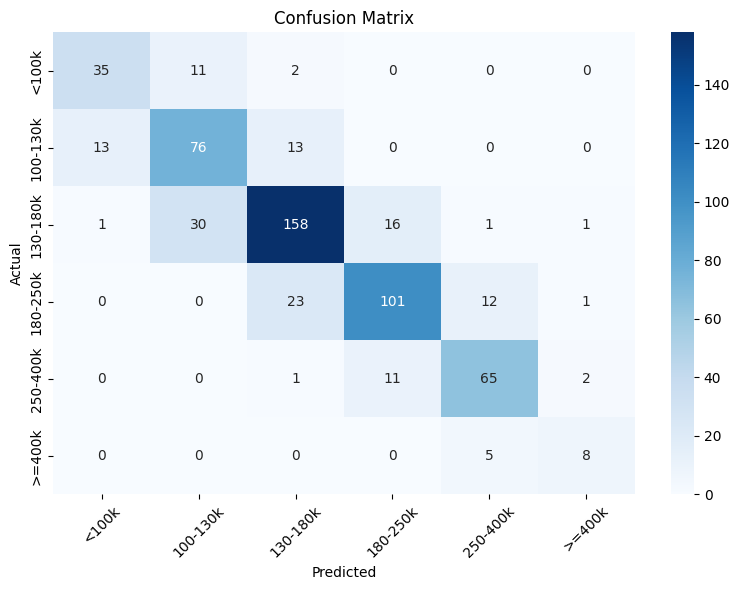

In [22]:
cm = confusion_matrix(y_te, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=enc.price_labels, yticklabels=enc.price_labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

To better visualize our model we will plot 2 graphs: ROC plot and an AUC plot

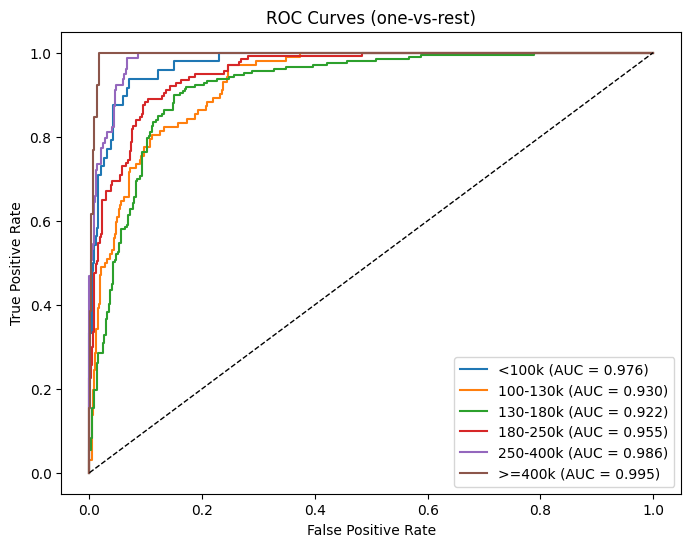

Macro AUC: 0.9605974336621509


In [23]:
y_te_bin = label_binarize(y_te, classes=range(enc.n_classes))

plt.figure(figsize=(8, 6))
for i in range(enc.n_classes):
    fpr, tpr, _ = roc_curve(y_te_bin[:, i], y_prob[:, i])
    auc = roc_auc_score(y_te_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f"{enc.price_labels[i]} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (one-vs-rest)")
plt.legend()
plt.show()

print("Macro AUC:", roc_auc_score(y_te_bin, y_prob, average='macro', multi_class='ovr'))

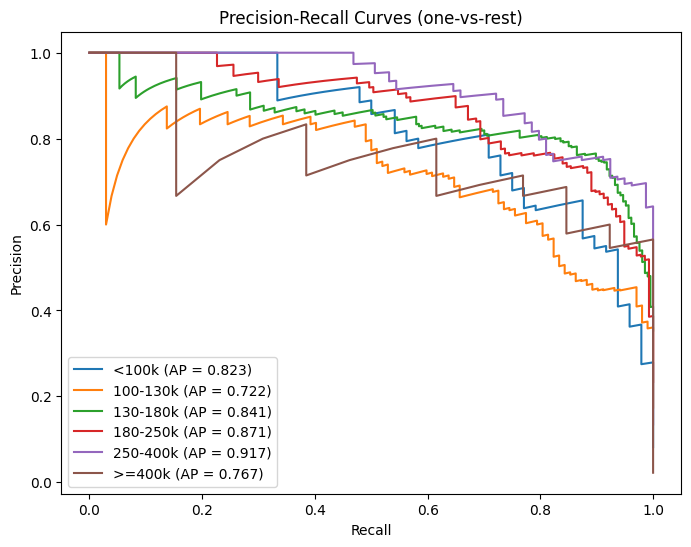

In [31]:
plt.figure(figsize=(8, 6))
for i in range(enc.n_classes):
    prec, rec, _ = precision_recall_curve(y_te_bin[:, i], y_prob[:, i])
    ap = average_precision_score(y_te_bin[:, i], y_prob[:, i])
    plt.plot(rec, prec, label=f"{enc.price_labels[i]} (AP = {ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves (one-vs-rest)")
plt.legend()
plt.show()

The AUC values look high for every class, including the rare ones. This is because the data is unbalanced. In one-vs-rest the negative side has thousands of samples, so the false positive rate stays low almost for free and the ROC curve looks better than the model is.


The precision-recall curves are the better version. Average precision drops for the small classes, because precision is computed only from the predicted positives and there are only a few of them.

For our problem the PR curves describe the model much better than the ROC ones.

---

Now we will find the best threshold by picking the threshold with the best one-vs-rest f1 for each class

In [24]:
def best_thresholds(y_bin, y_prob):
    # for each class, pick the threshold with the best one-vs-rest f1
    thresholds = []
    for i in range(y_prob.shape[1]):
        prec, rec, thr = precision_recall_curve(y_bin[:, i], y_prob[:, i])
        f1 = 2 * prec * rec / (prec + rec + 1e-9)
        # last point of the curve has no threshold
        best = f1[:-1].argmax()
        thresholds.append(thr[best])
    return np.array(thresholds)


thr = best_thresholds(y_te_bin, y_prob)

# rescale probabilities by the thresholds, then take the argmax
y_pred_thr = (y_prob / thr).argmax(axis=1)

print("Thresholds:", dict(zip(enc.price_labels, thr.round(3))))
print()
print("Macro F1 (argmax):    ", f1_score(y_te, y_pred, average='macro', zero_division=0))
print("Macro F1 (thresholds):", f1_score(y_te, y_pred_thr, average='macro', zero_division=0))
print()
print(classification_report(y_te, y_pred_thr, target_names=enc.price_labels, zero_division=0))

Thresholds: {'<100k': np.float32(0.649), '100-130k': np.float32(0.502), '130-180k': np.float32(0.315), '180-250k': np.float32(0.286), '250-400k': np.float32(0.263), '>=400k': np.float32(0.168)}

Macro F1 (argmax):     0.7337708193407283
Macro F1 (thresholds): 0.7390336658112243

              precision    recall  f1-score   support

       <100k       0.77      0.71      0.74        48
    100-130k       0.71      0.69      0.70       102
    130-180k       0.78      0.81      0.79       207
    180-250k       0.77      0.74      0.75       137
    250-400k       0.79      0.84      0.81        79
      >=400k       0.67      0.62      0.64        13

    accuracy                           0.76       586
   macro avg       0.75      0.73      0.74       586
weighted avg       0.76      0.76      0.76       586



`predict` takes the class with the highest probability, meaning that it uses a threshold of 1/6 for every class. picking the threshold that maximises
the one-vs-rest f1 per class and then dividing the probabilities by it, rare classes need less confidence to be chosen

As expected, the thresholds are lower for the small classes

However, the thresholds were chosen on the test set, so this macro-f1 is optimistic. In a real setup they would be tuned on a separate validation split and only then applied to the test data.

---

We will now compare the first tree and the best tree to see what they do differently

In [36]:
import os

os.environ["PATH"] += os.pathsep + r'C:\Program Files (x86)\Graphviz\bin'

c:\Users\shoml\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


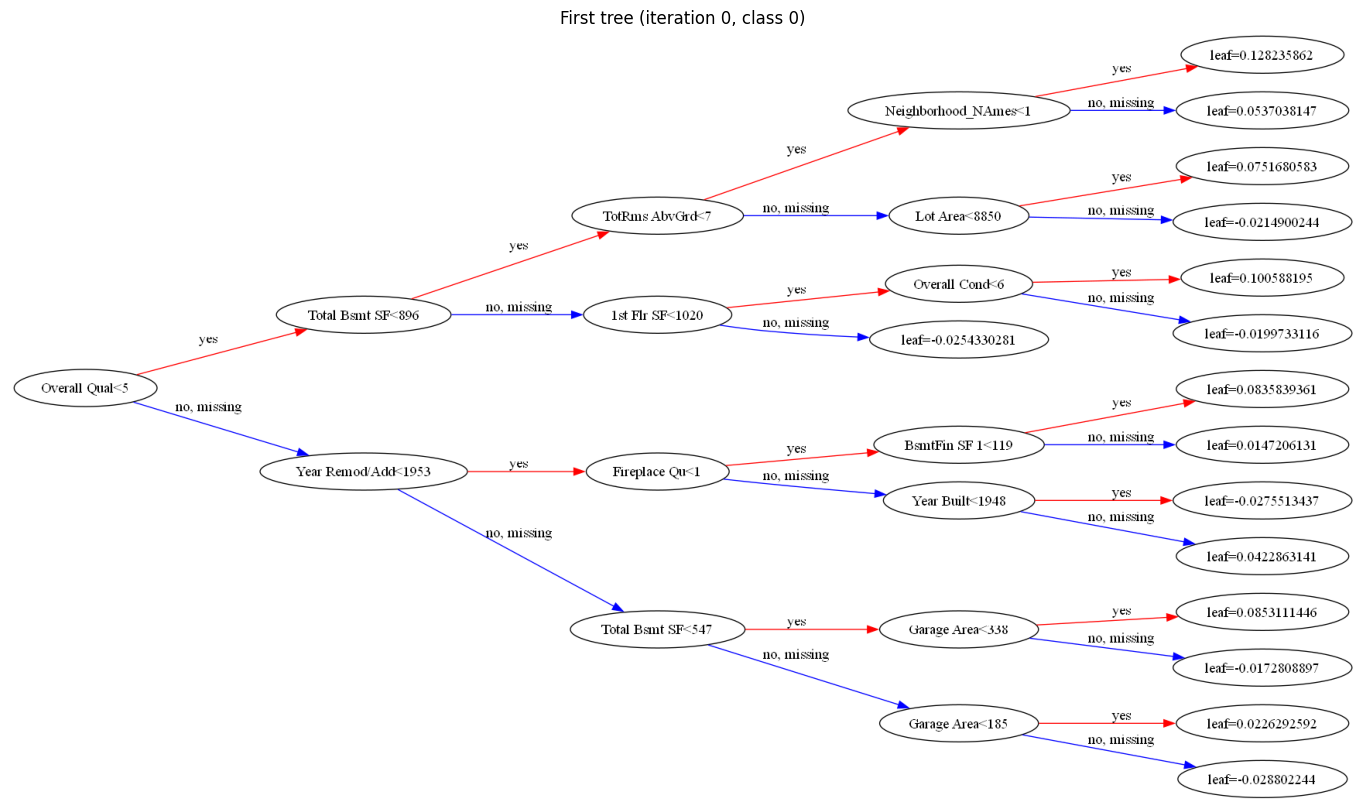

In [ ]:
fig, ax = plt.subplots(figsize=(20, 10))
xgb.plot_tree(model, num_trees=0, rankdir='LR', ax=ax)
ax.set_title("First tree (iteration 0, class 0)")
plt.show()

Best iteration: 299
Macro F1: 0.7171806937061751


c:\Users\shoml\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


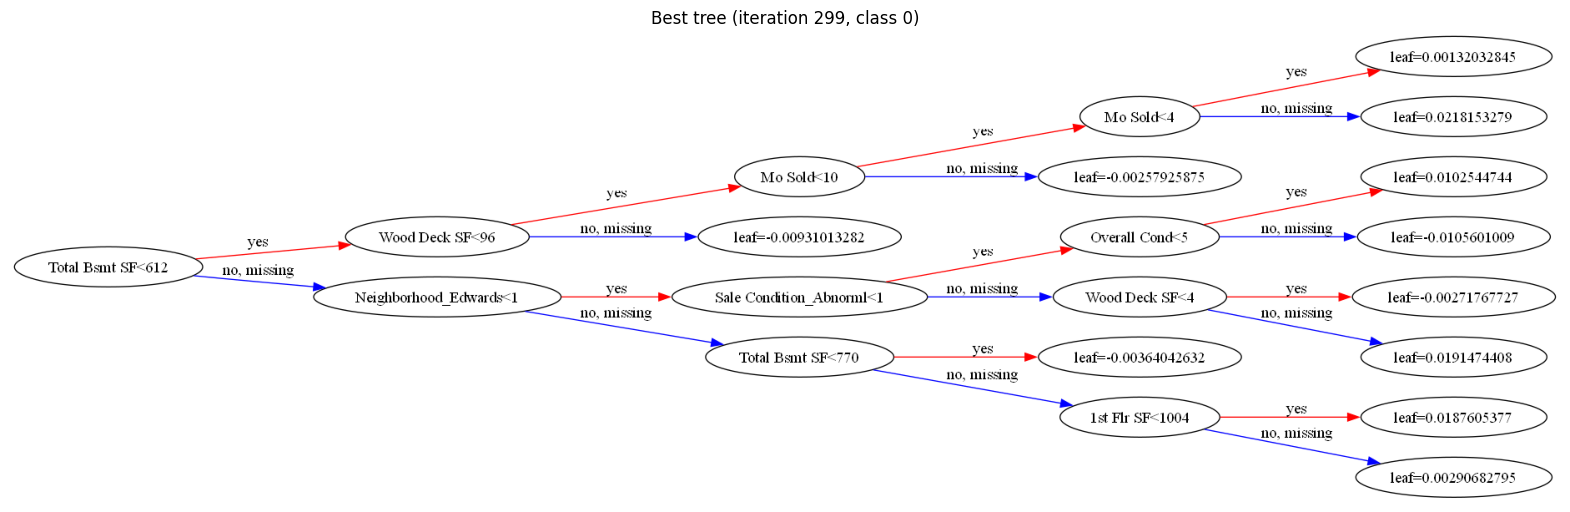

In [35]:
# early stopping on an inner validation split, not on the test set
X_fit, X_val, y_fit, y_val = train_test_split(
    X_tr, y_tr, test_size=0.2, random_state=42, stratify=y_tr
)
w_fit = np.sqrt(compute_sample_weight('balanced', y_fit))

es_model = make_model(n_estimators=1000, early_stopping_rounds=30)
es_model.fit(X_fit, y_fit, sample_weight=w_fit,
             eval_set=[(X_val, y_val)], verbose=False)

print("Best iteration:", es_model.best_iteration)
print("Macro F1:", f1_score(y_te, es_model.predict(X_te), average='macro', zero_division=0))

fig, ax = plt.subplots(figsize=(20, 10))
xgb.plot_tree(es_model, num_trees=es_model.best_iteration * enc.n_classes,
              rankdir='LR', ax=ax)
ax.set_title(f"Best tree (iteration {es_model.best_iteration}, class 0)")
plt.show()

The first tree splits on the strongest global signals (for example overall quality and living area). Its leaf values are large, because it has to move the prediction away from the initial guess

The tree at the best iteration looks different: it splits on narrower features and its leaf values are much smaller. By then most of the signal is already captured, so each new tree only corrects the residual errors

---

We will now analyze feature importance by plotting both the gain and split count graphs. This will give us an idea of which features are important for accurate predictions

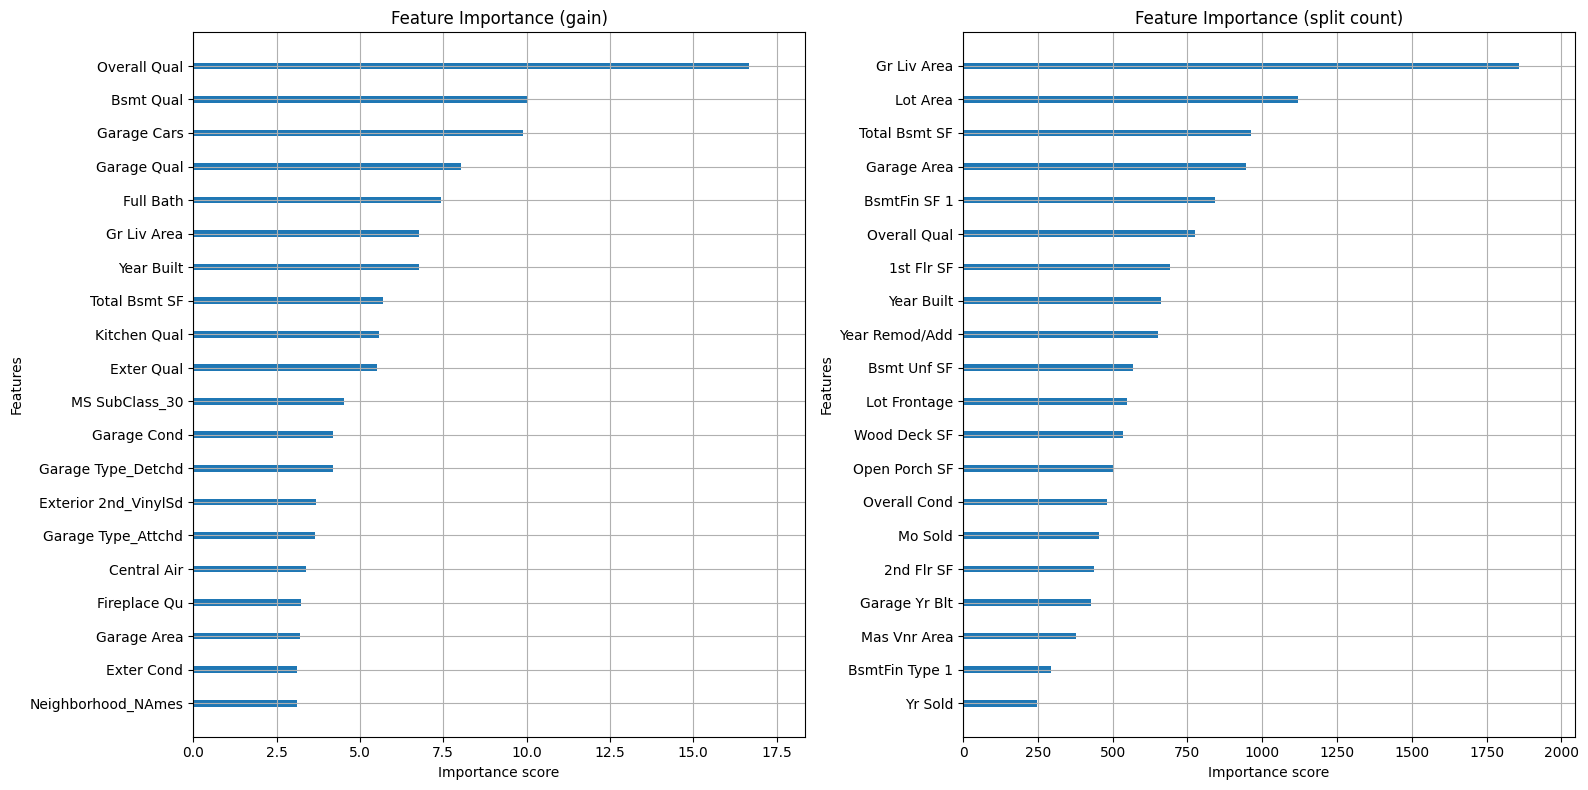

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))

xgb.plot_importance(model, importance_type='gain', max_num_features=20,
                    ax=ax[0], title="Feature Importance (gain)", show_values=False)
xgb.plot_importance(model, importance_type='weight', max_num_features=20,
                    ax=ax[1], title="Feature Importance (split count)", show_values=False)

plt.tight_layout()
plt.show()

gain - how much each feature reduced the loss when it was used. a feature used only a few times but in decisive splits scores high here

split count - how often the feature was used. for example, Gr. Liv Area is high because there are many possible cut points

the one-hot columns are the clearest case: a neighbourhood like "StoneBr" is rarely used, but it separates expensive houses very well

for explaining what actually increases the price, gain is the more useful view

---

We will now compare 5 strategies:
  - native NaN handling
  - low variance cols
  - add new features
  - removing features

In [29]:
def add_features(df):
    # extra features built from existing columns
    df = df.copy()
    df['House Age'] = df['Yr Sold'] - df['Year Built']
    df['Remod Age'] = df['Yr Sold'] - df['Year Remod/Add']
    df['Was Remodeled'] = (df['Year Remod/Add'] != df['Year Built']).astype(int)
    df['Total Baths'] = (df['Full Bath'] + 0.5 * df['Half Bath']
                         + df['Bsmt Full Bath'] + 0.5 * df['Bsmt Half Bath'])
    df['Total SF'] = df['Total Bsmt SF'] + df['Gr Liv Area']
    df['Has Pool'] = (df['Pool Area'] > 0).astype(int)
    return df


def make_data_v2(drop_low_variance=True, features=False, drop_redundant=False):
    # same as make_data, with optional feature engineering
    df = pp.clean(pp.load_raw(), drop_low_variance=drop_low_variance)
    if features:
        df = add_features(df)
    y = enc.make_target(df)
    X = df.drop(columns=enc.target_cols, errors='ignore')
    if drop_redundant:
        # Garage Yr Blt is almost the same as Year Built (see the heatmap)
        X = X.drop(columns=['Garage Yr Blt'], errors='ignore')
    return enc.encode_features(X), y

In [30]:
def eval_strategy(name, X, y, use_nan=False):
    # macro-f1 on a stratified 5-fold, same model everywhere
    X_in = X if use_nan else pd.DataFrame(
        SimpleImputer(strategy='median').fit_transform(X), columns=X.columns
    )
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_validate(make_model(), X_in, y, cv=cv,
                            scoring='f1_macro', n_jobs=-1)
    return {
        'strategy': name,
        'n_features': X.shape[1],
        'macro_f1': scores['test_score'].mean(),
        'std': scores['test_score'].std()
    }



strategies = []

Xa, ya = make_data_v2()
strategies.append(eval_strategy('baseline (median impute)', Xa, ya))
strategies.append(eval_strategy('native NaN handling', Xa, ya, use_nan=True))

Xb, yb = make_data_v2(drop_low_variance=False)
strategies.append(eval_strategy('keep low variance cols', Xb, yb))

Xc, yc = make_data_v2(features=True)
strategies.append(eval_strategy('with new features', Xc, yc))

Xd, yd = make_data_v2(features=True, drop_redundant=True)
strategies.append(eval_strategy('features, no Garage Yr Blt', Xd, yd))

strategy_results = pd.DataFrame(strategies).sort_values('macro_f1', ascending=False)
display(strategy_results)

,strategy,n_features,macro_f1,std
3,with new features,228,0.738939,0.018338
1,native NaN handling,222,0.738416,0.011851
4,"features, no Garage Yr Blt",227,0.736446,0.008175
2,keep low variance cols,247,0.735931,0.008729
0,baseline (median impute),222,0.734441,0.014519


All five land between 0.734 and 0.739, with standard deviations of 0.008-0.018. The differences are smaller than the noise between folds, so none of those strategies beats the others.

  - native NaN handling matches median imputation without any extra work.
  XGBoost learns a default direction for missing values at each split, so a
  missing `Lot Frontage` stays information instead of becoming a made-up number.

  - low variance columns change nothing. For example, `Utilities` is `AllPub` for 2927 of
  2930 houses, so the model never has a reason to split on it.

  - new features help slightly, but they mostly repackage what was already
  there: `House Age` is a linear transform of `Year Built`, `Total SF` is a sum
  of two columns. Trees can find these on their own

  - dropping Garage Yr Blt does not hurt, which confirms it was redundant
  with `Year Built`.
